# Worksheet 1: Represent a message $m$ as an $n$-qubit basis state $|m\rangle$

**Quantum Lock project, Task 1 of 5.** In this worksheet you will build, in this order:

1. the sizes: how many qubits $n$, the dimension $d$, the number of messages $M$
2. what a message $m$ is
3. how $m$ becomes bits, and which qubit holds which bit
4. the vector $|m\rangle$ in NumPy
5. a quantum register and an empty circuit
6. the gates that turn $|0\dots0\rangle$ into $|m\rangle$
7. a simulation that reads $m$ back

### How to use this worksheet

- **📖 Read** cells explain a concept. **✍️ On paper** cells ask you to work something out by hand first.
- **✏️ TODO** cells are yours: replace `None` or the `raise NotImplementedError` with your own code.
- **✅ Check** cells test what you wrote. They print ✅ (correct), ❌ (what is wrong, not how to fix it) or ⏳ (not done yet). **Don't move on until you get ✅.**
- **💡 Hints** are folded. Open them only if you are stuck; Hint 1 is gentle, the last one names the exact function or gate.
- **🔀 Options** tables list the different ways to do a step. Choose one, and write your choice and reason in the decision log at the end, which you can reuse in the report.


## 📖 0. The big picture

Alice wants to send Bob a message $m$. They share a short secret key $k$. Eve may grab the quantum state on the way.

```
 Alice                                              Bob
 m ──► |m⟩ ──► F ──► D_k ──► |ψ_{m,k}⟩ ──────────►  D_k† ──► F† ──► measure ──► m
      task 1   task 2  task 3    task 4     channel        task 5
                                               │
                                              Eve (no key)
```

**Notation map.** You'll need this in the report, because the paper and the brief use slightly different letters.

| Meaning                     | Paper (Lupo–Wilde–Lloyd, Sec. II) | Project brief                          | Worksheets                |
| --------------------------- | --------------------------------- | -------------------------------------- | ------------------------- | --------- | --------- | --- |
| number of messages          | $M$                               | $M$                                    | `M`                       |
| number of keys              | $K$                               | $K$ (called "$N$" in the reading list) | `K`                       |
| Hilbert-space dimension     | $d$                               | $d=2^n$                                | `d`                       |
| number of qubits            | (not used)                        | $n$                                    | `N`, `N_DEMO`             |
| basis index                 | $\omega = 1..d$                   |                                        | `x = 0..d-1`              |
| key-dependent phase unitary | $U_k$ (Eq. 16)                    | $D_k$                                  | `D_k`                     |
| Fourier basis vector        | $                                 | \tilde m\rangle$ (Eq. 17)              | $F                        | m\rangle$ |           |
| codeword                    | $                                 | \psi\_{mk}\rangle = U_k                | \tilde m\rangle$ (Eq. 18) | $D_kF     | m\rangle$ |     |

⚠️ The paper counts from 1. Python and the worksheets count from **0**.


## Setup


In [37]:
# Setup (given — nothing to solve here)
# If a package is missing:  !pip install qiskit matplotlib
import numpy as np
import matplotlib.pyplot as plt
import qiskit
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.quantum_info import Statevector, Operator, DensityMatrix
from qiskit.circuit.library import QFTGate, DiagonalGate, UnitaryGate

from project.proves.lock_checks import *     # the automatic checks + plot_circles (keep lock_checks.py in this folder)

np.set_printoptions(precision=3, suppress=True, linewidth=130)
print("Qiskit", qiskit.__version__, "ready")

Qiskit 2.5.2 ready


---

## Step 1.1: How many qubits?

📖 With $n$ qubits there are $2^n$ basis states, and each basis state can hold one message.

🔀 **Options**

| $n$ | basis states | good for                                                      |
| --- | ------------ | ------------------------------------------------------------- |
| 2   | 4            | doing everything by hand (4×4 matrices)                       |
| 3   | 8            | printing and drawing every amplitude                          |
| 4–5 | 16–32        | medium experiments                                            |
| 6   | 64           | the brief's suggested project size                            |
| 8   | 256          | upper limit in the brief (it gets expensive, see worksheet 3) |

A good plan is to keep **two** sizes: a tiny one for looking at things and the project one. Everything you write later should take `n` as an argument, so switching is easy.


In [38]:
# ✏️ TODO 1.1: choose a small "demo" size and the project size
N_DEMO = 4
N      = 6

In [39]:
check_n(N_DEMO, N)

✅ sizes n — N_DEMO = 4, N = 6


True

## Step 1.2: Dimension $d$ and number of messages $M$

📖 $d$ is the **length of the state vector**: one complex amplitude per basis state. $M$ is how many messages you actually use, and it can't be more than $d$.

🔀 **Options for $M$**

| Option | Choice | Comment                                                                                                                 |
| ------ | ------ | ----------------------------------------------------------------------------------------------------------------------- |
| A      | $M=d$  | Use every basis state. The brief's "simplest experiment"                                                                |
| B      | $M<d$  | Use a subset. The paper's _first_ protocol needs $M\ll d$. Ours is the _second_ one (Sec. II.A), where $M=d$ is allowed |

✍️ **On paper first:** for your two sizes, what are $d$ and $\log_2 M$ (bits per message)?


In [40]:
# ✏️ TODO 1.2: compute the dimensions (use N_DEMO and N, not hard-coded numbers)
d_demo = 16
d      = 64
M      = 64

In [41]:
check_dims(N_DEMO, N, d_demo, d, M)

✅ dimensions d and M — d_demo = 16, d = 64, M = 64


True

<details><summary>💡 Hint 1</summary>

$n$ qubits give $2^n$ basis states.

</details>

<details><summary>💡 Hint 2</summary>

Python power is `**`.

</details>


## Step 1.3: What _is_ a message?

📖 For the quantum part a message is just an **integer** $m\in\{0,\dots,M-1\}$. Text or other data would first be turned into such integers on the normal computer.

🔀 **Options**

| Option | Message source                                                                                      |
| ------ | --------------------------------------------------------------------------------------------------- |
| A      | integers $0..M-1$ directly (all the experiments only need this)                                     |
| B      | text: 1 character = 1 integer using a 64-symbol alphabet (6 bits). Fun for the report, and optional |


In [42]:
# ✏️ TODO 1.3a: the list of all messages 0, 1, ..., M-1
messages = list(range(64))

In [43]:
check_messages(messages, M)

✅ message list — 64 messages


True

<details><summary>💡 Hint 1</summary>

There is a built-in that produces 0, 1, …, M−1. Turn it into a list.

</details>

<details><summary>💡 Hint 2</summary>

`list(range(...))`

</details>


**Optional 1.3b (text).** Make a 64-character alphabet string, and two functions that convert text → list of integers and back. Skip this if you like.


In [44]:
# ✏️ TODO 1.3b (optional)
ALPHABET = None      # a string with 64 different characters, e.g. letters, digits, space, '.'

def text_to_messages(text):
    raise NotImplementedError

def messages_to_text(ms):
    raise NotImplementedError

In [45]:
check_text(text_to_messages, messages_to_text, ALPHABET)

⏳ text <-> messages: TODO not done yet (still None)


False

<details><summary>💡 Hint 1</summary>

26 + 26 + 10 + 2 = 64.

</details>

<details><summary>💡 Hint 2</summary>

A string has `.index(ch)`, and you can index a string with an integer.

</details>


## Step 1.4: From an integer to bits, and which qubit holds which bit

📖 Any $m$ can be written as $m=\sum_{q=0}^{n-1} b_q 2^q$ with bits $b_q\in\{0,1\}$. **Qubit $q$ will hold bit $b_q$.**

Qiskit's convention (_little-endian_) is the same as the course's `0x1, 0x2, 0x4` labels:

- qubit 0 holds $b_0$, worth 1 (`0x1`)
- qubit 1 holds $b_1$, worth 2 (`0x2`)
- qubit 2 holds $b_2$, worth 4 (`0x4`)
- a printed bitstring reads $b_{n-1}\dots b_1b_0$, so **qubit 0 is the rightmost character**.

🔀 **Options**

| Option | Convention                    | Comment                                                       |
| ------ | ----------------------------- | ------------------------------------------------------------- |
| A      | little-endian (Qiskit native) | no conversions anywhere                                       |
| B      | big-endian (some textbooks)   | you'd have to reverse things everywhere, a classic bug source |

✍️ **On paper first:** fill in the list `[b_0, b_1, b_2]` for these messages ($n=3$).


In [46]:
# ✏️ TODO 1.4a: fill the blanks by hand (no code!), lists are [b_0, b_1, b_2]
my_table = {
    1: [1, 0, 0],
    4: [0, 0, 1],
    5: [1, 0, 1],
    6: [0, 1, 1],
}

In [47]:
check_bit_table(my_table)

✅ bit table on paper


True

Now write a function that does the same for any $m$ and $n$. It returns `[b_0, b_1, ..., b_{n-1}]`, with list index = qubit number.


In [48]:
# ✏️ TODO 1.4b
def bits_of(m, n):
    raise NotImplementedError

In [49]:
check_bits_of(bits_of)

⏳ bits_of(m, n): TODO not done yet (function still raises NotImplementedError)


False

<details><summary>💡 Hint 1</summary>

Bit $q$ of $m$ answers: is the $2^q$ part present? You can get it by shifting $m$ right by $q$ places and looking at the last bit.

</details>

<details><summary>💡 Hint 2</summary>

Operators `>>` (shift) and `& 1` (keep last bit). Or `format(m, '0nb')` and then read the string **from the right**.

</details>


## Step 1.5: The vector $|m\rangle$

📖 $|m\rangle$ is a **computational-basis state**: a vector of length $d$ with a single 1 in position $m$ and 0 everywhere else.

$$|m\rangle=(0,\dots,0,\underbrace{1}_{\text{index } m},0,\dots,0)^T$$

Two properties matter for the whole project:

- **normalized**: $\langle m|m\rangle = 1$
- **orthogonal**: $\langle m'|m\rangle=0$ if $m'\ne m$. Orthogonal states can be told apart perfectly, and that's what will let Bob read $m$ at the end.

🔀 **Options to build it**

| Option | How                                                               |
| ------ | ----------------------------------------------------------------- |
| A      | an array of zeros, then set one entry to 1                        |
| B      | tensor (Kronecker) product of single-qubit kets (course deck 0.9) |
| C      | `Statevector.from_int(m, d)`                                      |

Write A as your working function. B is the next exercise. C you can use to compare.


In [68]:
# ✏️ TODO 1.5a: |m> as a complex NumPy array of length d
def ket(m, d):
    return Statevector.from_int(m, d)
    #raise NotImplementedError

In [69]:
check_ket(ket)

✅ ket(m, d) — length, normalization and position all correct


True

<details><summary>💡 Hint 1</summary>

Start from an array of zeros of the right length and **complex** type.

</details>

<details><summary>💡 Hint 2</summary>

`np.zeros(d, dtype=complex)`, then assign index `m`.

</details>


**1.5b: the same state from qubits.** $|m\rangle$ is the tensor product of single-qubit states. In Qiskit's ordering the **highest** qubit is the **leftmost** factor:

$$|m\rangle = |b_{n-1}\rangle\otimes\dots\otimes|b_1\rangle\otimes|b_0\rangle$$

✍️ On paper: $5 = $ `101`, so $|5\rangle = |1\rangle\otimes|0\rangle\otimes|1\rangle$. Write the 8-vector you expect.

Now build it in code from `ket0 = [1,0]` and `ket1 = [0,1]`.


In [85]:
# ✏️ TODO 1.5b: |5> for 3 qubits as a Kronecker product
ket0 = np.array([1, 0], dtype=complex)
ket1 = np.array([0, 1], dtype=complex)
v_kron = np.kron(ket1, np.kron(ket0, ket1))

In [86]:
check_kron5(v_kron)

✅ |5> from tensor products — the highest qubit is the LEFT factor of the Kronecker product


True

<details><summary>💡 Hint 1</summary>

You need three factors, highest qubit first.

</details>

<details><summary>💡 Hint 2</summary>

`np.kron(a, np.kron(b, c))`. Which of ket0 / ket1 goes in each place?

</details>


**1.5c: orthonormality.** Build the $M\times M$ matrix $G$ with $G_{a,b}=\langle a|b\rangle$ (the _Gram matrix_). If the states are orthonormal, $G$ must be the identity.


In [54]:
# ✏️ TODO 1.5c: Gram matrix of all message states (use your ket and d, M)
G = None

In [55]:
check_gram(G, M)

⏳ Gram matrix of the messages: TODO not done yet (still None)


False

<details><summary>💡 Hint 1</summary>

Inner product of complex vectors: conjugate the first one.

</details>

<details><summary>💡 Hint 2</summary>

`np.vdot(u, v)` already conjugates `u`. Use a double list comprehension, or stack all kets as columns of a matrix $A$ and compute $A^\dagger A$.

</details>


## Step 1.6: Registers and an empty circuit

📖 A **register** is a named group of qubits (or classical bits). The brief: _only the message register must be quantum, and the key can stay a classical number._

🔀 **Options**

| Option | Registers                                          | Use when                                                                                          |
| ------ | -------------------------------------------------- | ------------------------------------------------------------------------------------------------- |
| A      | one `QuantumRegister(n, "msg")`, no classical bits | exact simulation with `Statevector` (tasks 1–5). `Statevector` refuses circuits with measurements |
| B      | + `ClassicalRegister(n)`                           | you want shots or real hardware (add `measure` at the end)                                        |
| C      | + a quantum key register                           | only for an advanced "key in superposition" model. Not needed                                     |


In [87]:
# ✏️ TODO 1.6: a quantum register called "msg" with N_DEMO qubits, and a circuit that uses it
qr = QuantumRegister(4, "msg")
qc = QuantumCircuit(qr)

In [88]:
check_register(qc, N_DEMO)
print(qc.draw('text') if qc is not None else '')

✅ register + circuit — register 'msg' with 4 qubits, 0 classical bits
       
msg_0: 
       
msg_1: 
       
msg_2: 
       
msg_3: 
       


<details><summary>💡 Hint 1</summary>

Two constructors: first the register, then the circuit taking the register.

</details>

<details><summary>💡 Hint 2</summary>

`QuantumRegister(size, name)` and `QuantumCircuit(qr)`.

</details>


## Step 1.7: Which gates prepare $|m\rangle$?

📖 Every circuit starts in $|0\dots0\rangle=|0\rangle$. You must reach $|m\rangle$.

✍️ **Before coding, answer for yourself:** which of the course gates do you need?

| Gate (course Module II) | What it does               |
| ----------------------- | -------------------------- | ----------------------- | ---------------------- |
| NOT / X                 | $                          | 0\rangle\leftrightarrow | 1\rangle$ on one qubit |
| HAD / H                 | makes a superposition      |
| PHASE, Z, S, T          | change phases only         |
| CNOT, CCNOT             | conditional flips          |
| WRITE (QPU instruction) | sets a register to a value |

Questions to settle first: which qubits must change for $m=5$ with $n=3$? Would H be OK? Why or why not?

🔀 **Options to build it**

| Option | Code idea                          | Pros / cons                                                                           |
| ------ | ---------------------------------- | ------------------------------------------------------------------------------------- |
| A      | one gate per qubit whose bit is 1  | transparent, at most $n$ gates, unitary, runs on hardware (= course WRITE)            |
| B      | `qc.prepare_state(m)`              | one line, but hides what happens                                                      |
| C      | `qc.initialize(...)`               | includes a **reset**, which is not unitary, so the circuit can't be inverted later ❌ |
| D      | no circuit: `Statevector.from_int` | fine for simulation, but not a circuit                                                |

The check below accepts A or B (not C).


In [102]:
# ✏️ TODO 1.7: return an n-qubit circuit that prepares |m> from |0...0>
def encode_message(m, n):
    """Return an n-qubit circuit preparing |m> from |0...0>."""
    if not (0 <= m < 2**n):
        raise ValueError(f"m={m} does not fit in n={n} qubits")

    qr = QuantumRegister(n, "msg")
    qc = QuantumCircuit(qr)

    for q in range(n):
        if (m >> q) & 1:
            qc.x(qr[q])

    return qc

In [103]:
check_encode(encode_message)

✅ encode_message(m, n) — every message prepares the right basis state (n = 3 and 6)


True

<details><summary>💡 Hint 1</summary>

Make a fresh register + circuit inside the function (like Step 1.6), then decide for each qubit whether it needs to change.

</details>

<details><summary>💡 Hint 2</summary>

Your `bits_of(m, n)` from Step 1.4 tells you which qubits; the gate is the course's NOT.

</details>

<details><summary>💡 Hint 3</summary>

`qc.x(qubit)` for every qubit whose bit is 1.

</details>


Look at your circuit. How many gates does $m=5$ need? And $m=0$? And $m=2^n-1$?


In [104]:
# ✏️ TODO: draw encode_message(5, N_DEMO)
qc5 = encode_message(5, N_DEMO)
print(qc5.draw("text"))

       ┌───┐
msg_0: ┤ X ├
       └───┘
msg_1: ─────
       ┌───┐
msg_2: ┤ X ├
       └───┘
msg_3: ─────
            


## Step 1.8: Simulate and read $m$ back

📖 Tools you'll use in every worksheet:

- `Statevector.from_instruction(circuit)`: the exact final state (no shots, no noise)
- `.data`: the amplitudes as a NumPy array (index = basis state)
- `.probabilities_dict()`: `{bitstring: probability}`, where the bitstring reads $q_{n-1}\dots q_0$
- `int(bitstring, 2)`: bitstring → integer

Do it for $m = 6$ with `N_DEMO` qubits. 6 is a good test because `110` is **not** a palindrome, so a reversed bit order would show up.


In [105]:
# ✏️ TODO 1.8: simulate encode_message(6, N_DEMO), print the probabilities, and turn the
# most likely bitstring into an integer
sv = None
m_decoded = None

qc6 = encode_message(6, N_DEMO)
sv = Statevector.from_instruction(qc6)

probs = sv.probabilities_dict()
print("probabilities:", probs)

m_decoded = int(max(probs, key=probs.get), 2)
print("decoded m =", m_decoded)

probabilities: {np.str_('0110'): np.float64(1.0)}
decoded m = 6


In [106]:
check_readout(m_decoded, 6)

✅ reading back the result — m = 6


True

<details><summary>💡 Hint 1</summary>

Get the dict, pick the key with the largest value.

</details>

<details><summary>💡 Hint 2</summary>

`max(probs, key=probs.get)` gives that key. Then `int(key, 2)`.

</details>


## Step 1.9: Test every message

📖 One example can hide bugs. Write a loop over **all** $m$ (for both sizes) that asserts your circuit's state equals `ket(m, d)`. The check in Step 1.7 already did this for you, but writing the loop yourself is the pattern you'll reuse in worksheets 4–5.


In [107]:
# ✏️ TODO 1.9: loop over n in (N_DEMO, N) and all m; compare Statevector data with ket(m, 2**n)

for n in (N_DEMO, N):
    d_n = 2**n
    for m in range(d_n):
        sv_n = Statevector.from_instruction(encode_message(m, n))
        target = ket(m, d_n)

        # ket may return either a Statevector or a NumPy array
        target_data = target.data if hasattr(target, "data") else np.asarray(target)

        assert np.allclose(sv_n.data, target_data), f"failed for n={n}, m={m}"

print("✅ all message encodings match ket(m, d)")

✅ all message encodings match ket(m, d)


<details><summary>💡 Hint 1</summary>

`np.allclose(a, b)` compares arrays with floating-point tolerance. Put it inside `assert`.

</details>


## Step 1.10: Look at it in circle notation

📖 `plot_circles(state, title)` (from `lock_checks`) draws the course's circle notation: filled area ∝ probability, and the line = phase (0 points up).

✍️ Predict first: what does $|5\rangle$ look like for $n=3$? Then plot it. Remember this picture; after the QFT in worksheet 2 it changes completely.


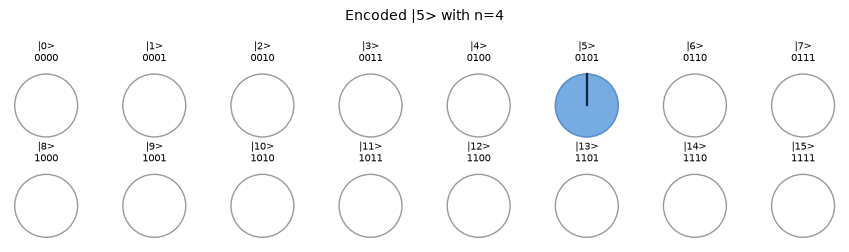

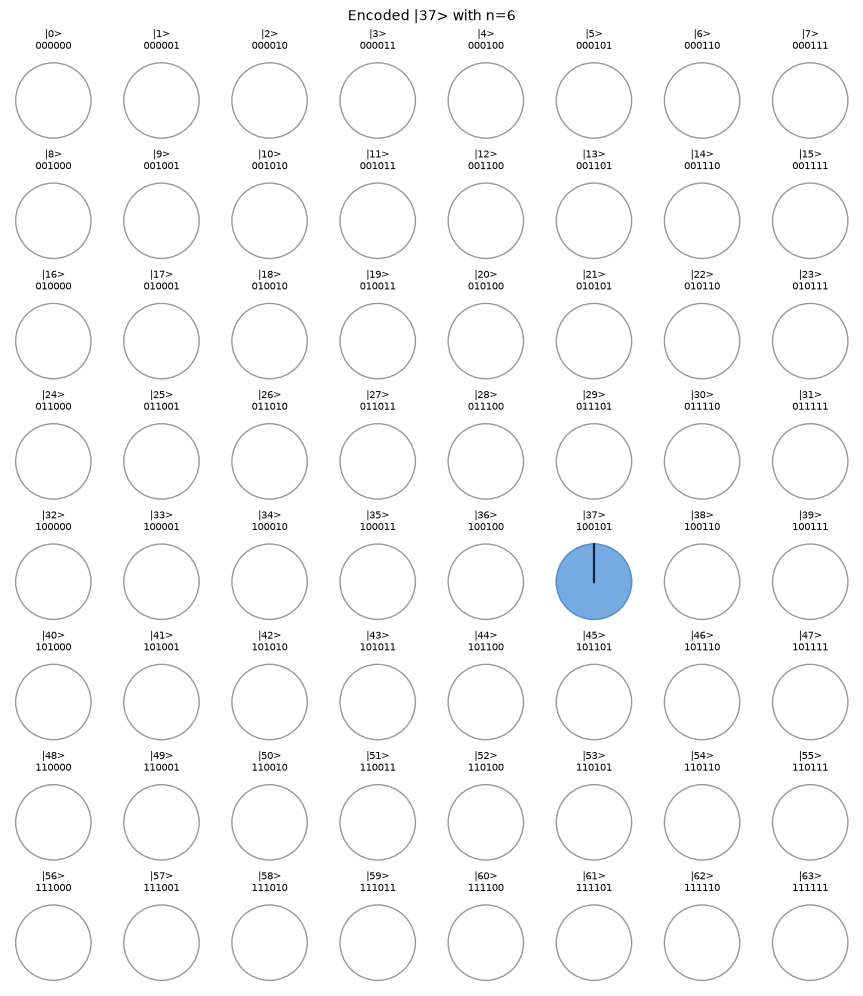

In [108]:
# ✏️ TODO 1.10: plot your encoded |5> (N_DEMO) and |37> (N)
sv5 = Statevector.from_instruction(encode_message(5, N_DEMO))
plot_circles(sv5, f"Encoded |5> with n={N_DEMO}")
plt.show()

sv37 = Statevector.from_instruction(encode_message(37, N))
plot_circles(sv37, f"Encoded |37> with n={N}")
plt.show()

---

## Self-check questions

1. How many X gates does $|63\rangle$ need with $n=6$? And $|0\rangle$?
2. Which qubit flips for $m=4$, $n=3$?
3. Why can't a Hadamard be part of the encoder?
4. Why is `initialize` a bad choice if we want to invert the whole circuit later?

<details><summary>Answers</summary>

1. Six X gates for 63 = `111111`; none for 0.
2. Qubit 2 (`0x4`).
3. It makes a superposition, so it would encode several messages at once.
4. It contains a reset, which is not unitary.
</details>

## Decision log (copy into your report notes)

| Step          | Options                                     | My choice | Why |
| ------------- | ------------------------------------------- | --------- | --- |
| 1.1 sizes $n$ | 2…8                                         |           |     |
| 1.2 $M$       | $M=d$ / $M<d$                               |           |     |
| 1.3 messages  | integers / text                             |           |     |
| 1.4 bit order | little / big endian                         |           |     |
| 1.6 registers | Q only / Q+C / +key                         |           |     |
| 1.7 encoder   | X gates / prepare_state / initialize / none |           |     |

✅ When every check above is green, continue with **Worksheet 2 (QFT)**. You'll paste `ket` and `encode_message` there.
